# Lunar crustal magnetic field with landing sites

Three-panel figure of the Moon's crustal magnetic field: (a) near side, (b) far side and (c) south polar zoom.
It shows the `T2015_449` total field at 30 km altitude over LOLA topographic shading, with past soft landings
and NASA's Artemis candidate landing regions marked.

This notebook needs no other files. All site coordinates are in the cells below, and the two models download
automatically on the first run (about 20 MB, then cached). The saved outputs let you read it without running it.

## Setup

Install from conda-forge, because `pygmt` needs the GMT library. These are the versions the figure was made with:

```
conda create -n lunar-maps -c conda-forge python=3.11 pyshtools=4.13.1 pygmt=0.15.0 gmt=6.4.0 numpy=1.26 ghostscript xarray scipy pooch netcdf4 jupyterlab ipywidgets
conda activate lunar-maps
jupyter lab
```

Then run all cells. The figure is saved next to this notebook as `Mag_near_far_landings.png` and `.eps`.

## Choices worth knowing

- **Color scale:** all panels share 0-10 nT (`cmap_low`, `cmap_high`). The field in panel c only reaches about 3 nT.
- **Views:** near side centered on 0E, 10S and far side on 180E, 10S, so that every landing site is visible.
  They were announced as candidate landing regions for crewed Artemis exploration missions.
  As of October 2026, NASA has not made a final site selection decision.
  October 2026 NASA has not made a final site decision.
- **Artemis box positions are measured, not published.** NASA gives no coordinates, so they are read from NASA's
  region map. The last cell of this notebook checks that calibration against LOLA topography.

## Sources

- Models: `T2015_449` (Tsunakawa et al., 2015) and `LOLA_shape` (Wieczorek, 2024), through pyshtools datasets.
- Landing sites: [Wikipedia, List of artificial objects on the Moon](https://en.wikipedia.org/wiki/List_of_artificial_objects_on_the_Moon),
  except IM-1, which uses the [NASA LRO position](https://www.nasa.gov/missions/lro/nasas-lro-images-intuitive-machines-odysseus-lander/).
- Artemis regions: [NASA release, Oct 2024](https://www.nasa.gov/news-release/nasa-provides-update-on-artemis-moon-landing-regions/),
  [region map](https://www.nasa.gov/wp-content/uploads/2024/10/artemis-landing-region-candidates.jpg),
  [George et al., LPSC 2026, abstract 1901](https://www.hou.usra.edu/meetings/lpsc2026/pdf/1901.pdf).
- Artemis status: [SpacePolicyOnline, Oct 2026](https://spacepolicyonline.com/news/nasa-is-full-steam-ahead-on-artemis/).


In [1]:
import numpy as np
import pyshtools as pysh
import pygmt
import xarray as xr
from scipy.ndimage import map_coordinates

pysh.utils.figstyle(rel_width=0.75)  # set some matplotlib parameters for better looking plots

In [2]:
clm = pysh.datasets.Moon.LOLA_shape(lmax=1439)
clm.coeffs[0,0,0] = 0.
grid_topo = clm.expand()

glm = pysh.datasets.Moon.T2015_449()
r = glm.r0 + 30.e3
grid_mag = glm.expand(a=r, lmax=1439)
total_grid = grid_mag.total

In [3]:
# Soft landings in date order: (number, name, year, lat, lon, crewed). * landed damaged or tipped over.
# Number 18 is Luna 23, which landed 1974-11-06; some landing maps label it Luna 22, which was an orbiter.
sites = [
    ( 1, 'Luna 9',         1966,   7.08,  -64.37, False),
    ( 2, 'Surveyor 1',     1966,  -2.474, -43.339, False),
    ( 3, 'Luna 13',        1966,  18.87,  -62.05, False),
    ( 4, 'Surveyor 3',     1967,  -3.015, -23.418, False),
    ( 5, 'Surveyor 5',     1967,   1.461,  23.195, False),
    ( 6, 'Surveyor 6',     1967,   0.4743, -1.4275, False),
    ( 7, 'Surveyor 7',     1968, -40.98,  -11.514, False),
    ( 8, 'Apollo 11',      1969,   0.6741, 23.473, True),
    ( 9, 'Apollo 12',      1969,  -3.0124, -23.4216, True),
    (10, 'Luna 16',        1970,  -0.68,   56.3, False),
    (11, 'Luna 17',        1970,  38.28,  -35.0, False),
    (12, 'Apollo 14',      1971,  -3.6453, -17.4714, True),
    (13, 'Apollo 15',      1971,  26.1322,  3.6339, True),
    (14, 'Luna 20',        1972,   3.57,   56.5, False),
    (15, 'Apollo 16',      1972,  -8.973,  15.5002, True),
    (16, 'Apollo 17',      1972,  20.1908, 30.7717, True),
    (17, 'Luna 21',        1973,  25.85,   30.45, False),
    (18, 'Luna 23*',       1974,  12.75,   62.2, False),
    (19, 'Luna 24',        1976,  12.75,   62.2, False),
    (20, "Chang'e 3",      2013,  44.12,  -19.51, False),
    (21, "Chang'e 4",      2019, -45.4561, 177.5885, False),
    (22, "Chang'e 5",      2020,  43.0576, -51.9161, False),
    (23, 'Chandrayaan-3',  2023, -69.373,  32.319, False),
    (24, 'SLIM',           2024, -13.316,  25.251, False),
    (25, 'IM-1*',          2024, -80.13,    1.44, False),
    (26, "Chang'e 6",      2024, -41.6385, -153.9852, False),
    (27, 'Blue Ghost M1',  2025,  18.5623, 61.8103, False),
    (28, 'IM-2*',          2025, -84.7906, 29.1957, False),
]

# Number labels: (text, site number, dx, dy) with offsets in points from the marker
near_labels = [
    ('1', 1, -10, 3), ('2', 2, 0, -12), ('3', 3, -10, 3), ('4,9', 4, -8, 12), ('5,8', 5, -5, 12),
    ('6', 6, 0, 12), ('7', 7, 0, 12), ('10', 10, 4, -11), ('11', 11, 0, 12), ('12', 12, 8, -11),
    ('13', 13, 0, 12), ('14', 14, 12, -3), ('15', 15, 0, -13), ('16', 16, -6, -12), ('17', 17, 0, 12),
    ('18,19', 18, 21, 0), ('20', 20, 0, 12), ('22', 22, 0, 12), ('23', 23, 12, 6), ('24', 24, 12, -6),
    ('25', 25, -14, 7), ('27', 27, 12, 7), ('28', 28, 14, 6),
]
far_labels = [('21', 21, 0, 12), ('26', 26, 0, 12)]
zoom_labels = [('IM-1', 25, 21, 0), ('IM-2', 28, 3, 12)]

In [4]:
# Artemis candidate regions. NASA gives no coordinates, so these are pixel boxes (x0, x1, y0, y1) read from
# NASA's region map (1430 x 1105 px, URL in the last cell). Calibration: pole marker at pixel (746, 761),
# scale bar 3.6 px/km, 0 deg E up. The last cell checks this against LOLA topography.
artemis_boxes = {
    'Peak near Cabeus B':  (64, 141, 473, 550),
    'Haworth':             (555, 668, 382, 494),
    'Malapert Massif':     (705, 786, 287, 367),
    'Mons Mouton Plateau': (920, 1199, 126, 337),
    'Mons Mouton':         (978, 1038, 308, 370),
    'Nobile Rim 1':        (1010, 1085, 330, 405),
    'Nobile Rim 2':        (1271, 1348, 383, 461),
    'de Gerlache Rim 2':   (535, 613, 640, 719),
    'Slater Plain':        (960, 1037, 902, 980),
}
X0, Y0, PX_PER_KM = 746, 761, 3.6
R_MOON = 1737.4  # km


def polar_km_to_lonlat(x, y):
    # South polar stereographic: x, y in km from the pole, with 0 deg E along +y
    lat = -90 + np.degrees(2*np.arctan(np.hypot(x, y) / (2*R_MOON)))
    lon = np.degrees(np.arctan2(x, y))
    return lon, lat


def box_to_lonlat(box):
    x0, x1, y0, y1 = box
    xs = (np.array([x0, x1, x1, x0, x0]) - X0) / PX_PER_KM
    ys = (Y0 - np.array([y0, y0, y1, y1, y0])) / PX_PER_KM
    return polar_km_to_lonlat(xs, ys)


for name, box in artemis_boxes.items():
    x, y = (box[0] + box[1])/2, (box[2] + box[3])/2
    lon, lat = polar_km_to_lonlat((x - X0)/PX_PER_KM, (Y0 - y)/PX_PER_KM)
    print(f'{name:20s} center {lat:7.2f} deg, {lon:7.2f} deg E')

Peak near Cabeus B   center  -83.68 deg,  -68.81 deg E
Haworth              center  -86.80 deg,  -22.61 deg E
Malapert Massif      center  -86.03 deg,   -0.07 deg E
Mons Mouton Plateau  center  -84.37 deg,   30.63 deg E
Mons Mouton          center  -85.45 deg,   31.83 deg E
Nobile Rim 1         center  -85.46 deg,   37.46 deg E
Nobile Rim 2         center  -83.98 deg,   58.97 deg E
de Gerlache Rim 2    center  -88.26 deg,  -64.65 deg E
Slater Plain         center  -87.16 deg,  125.48 deg E


In [5]:
# Colormap limits (nT), shared by all panels
cmap_low = 0
cmap_high = 10

# View centers (lon, lat)
near = (0, -10)
far = (180, -10)

# Polar zoom extent, km from the pole (0 deg E up)
zoom_x = (-240, 240)
zoom_y = (-100, 360)
zoom_step = 0.5  # km

# Layout (inches)
width = 4.5                # globe diameter
gap = 0.15                 # vertical space between globes
col_gap = 0.3              # space between globes and right column
zoom_w = 3.7               # polar zoom width
zoom_h = zoom_w * (zoom_y[1] - zoom_y[0]) / (zoom_x[1] - zoom_x[0])
stack_h = 2*width + gap

halo = '=~1.5p,white'      # white outline so labels read on any map color

# Font sizes (pt). The figure is 8.5 in wide, so at 180 mm journal width these print at about 83%.
fs_panel = 15     # panel titles
fs_site = 10.5    # site numbers on the globes
fs_region = 10    # region and lander names on the polar zoom
fs_legend = 11    # key and landing list
fs_small = 10     # scale bar and footnote
fs_cb_label = 12
fs_cb_annot = 11


def plot_field(fig, offset=[None, None], **kwargs):
    total_grid.plotgmt(fig=fig,
                       cmap_limits=[cmap_low, cmap_high],
                       cmap='roma',
                       cmap_reverse=True,
                       tick_interval=None,
                       shading=grid_topo,
                       offset=offset,
                       **kwargs)


def plot_sites(fig, numbers, size=8):
    for num, _, _, lat, lon, crewed in sites:
        if num in numbers:
            style = f'a{size + 3}p' if crewed else f'c{size}p'
            fig.plot(x=lon, y=lat, style=style, fill='white', pen='0.6p,black')


def plot_labels(fig, labels):
    font = f'{fs_site}p,Helvetica-Bold,black'
    coords = {s[0]: (s[4], s[3]) for s in sites}
    for text, num, dx, dy in labels:
        lon, lat = coords[num]
        fig.text(x=lon, y=lat, text=text, font=font + halo, justify='CM', offset=f'{dx}p/{dy}p', no_clip=True)


def plot_region(fig, box):
    lon, lat = box_to_lonlat(box)
    fig.plot(x=lon, y=lat, pen='2.4p,black')
    fig.plot(x=lon, y=lat, pen='1.2p,yellow')


def polar_sample(grid, xs, ys):
    # Sample an SHGrid on a km grid centered on the pole. Only rows south of 70S are used, and longitude
    # is padded so the interpolation wraps.
    rows = grid.data[int(160/180 * (grid.data.shape[0] - 1)):, :-1]
    pad = 4
    rows = np.hstack([rows[:, -pad:], rows, rows[:, :pad]])
    x, y = np.meshgrid(xs, ys)
    lon, lat = polar_km_to_lonlat(x, y)
    i = (lat + 70) / -20 * (rows.shape[0] - 1)
    j = (lon % 360) / 360 * (rows.shape[1] - 2*pad) + pad
    values = map_coordinates(rows, [i, j], order=3, mode='nearest')
    return xr.DataArray(values, coords={'y': ys, 'x': xs}, dims=['y', 'x'])


def globe(fig, center, offset=[None, None]):
    plot_field(fig, offset=offset, projection='Orthographic', central_longitude=center[0],
               central_latitude=center[1], width=width, grid=[30, 30])

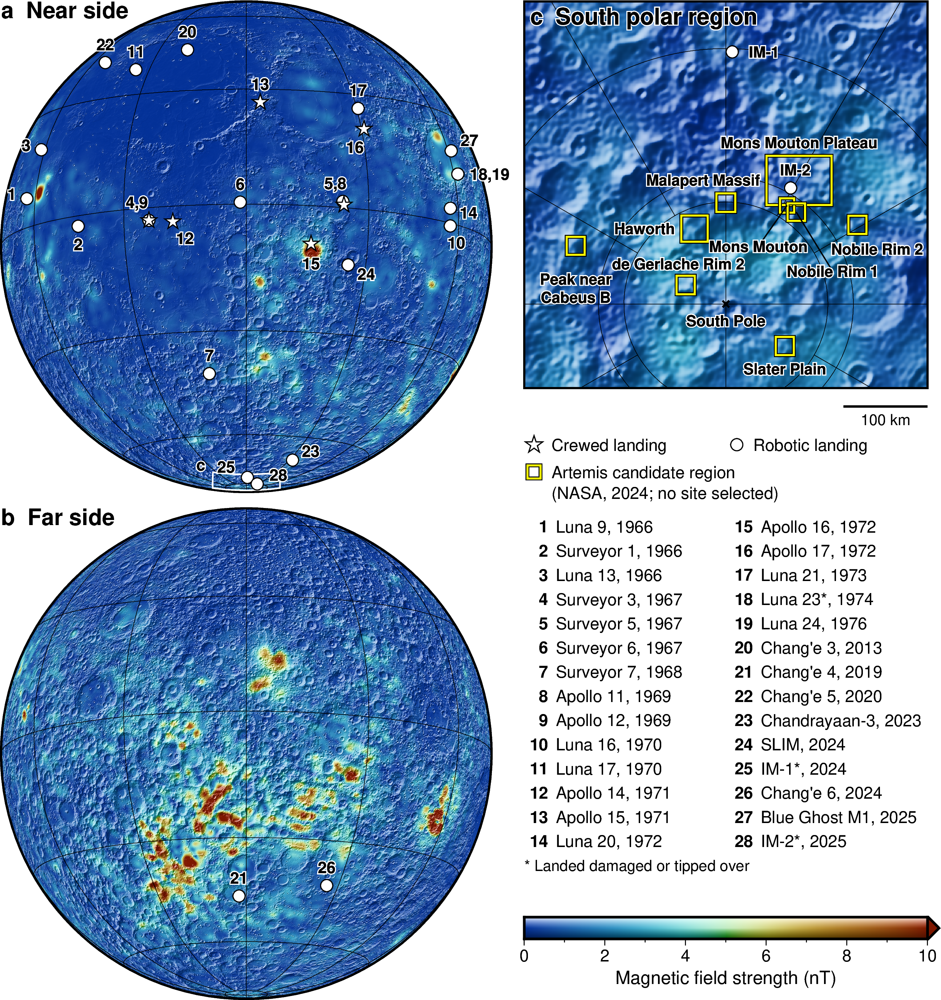

In [6]:
fig = pygmt.Figure()

# Corners of the polar zoom, for its region and its outline on panel a
(lon_ll, lat_ll) = polar_km_to_lonlat(zoom_x[0], zoom_y[0])
(lon_ur, lat_ur) = polar_km_to_lonlat(zoom_x[1], zoom_y[1])

# Panel a: near side
globe(fig, near)
xs = np.r_[np.linspace(*zoom_x, 50), np.full(50, zoom_x[1]), np.linspace(*zoom_x[::-1], 50), np.full(50, zoom_x[0])]
ys = np.r_[np.full(50, zoom_y[1]), np.linspace(*zoom_y[::-1], 50), np.full(50, zoom_y[0]), np.linspace(*zoom_y, 50)]
lon, lat = polar_km_to_lonlat(xs, ys)
fig.plot(x=lon, y=lat, pen='0.9p,white')
fig.text(x=lon[0], y=lat[0], text='c', font=f'{fs_site}p,Helvetica-Bold,black' + halo, justify='CM', offset='-8p/4p', no_clip=True)
plot_sites(fig, {s[0] for s in sites} - {21, 26})
plot_labels(fig, near_labels)
fig.text(position='TL', text='a  Near side', font=f'{fs_panel}p,Helvetica-Bold', justify='TL', no_clip=True)

# Panel b: far side
globe(fig, far, offset=[0, -(width + gap)])
plot_sites(fig, {21, 26})
plot_labels(fig, far_labels)
fig.text(position='TL', text='b  Far side', font=f'{fs_panel}p,Helvetica-Bold', justify='TL', no_clip=True)

# Panel c: south polar zoom
# plotgmt streaks here: grdimage sets its resolution from the lat/lon rows in this small polar region, so
# the field and hillshade are resampled onto a regular km grid first. The stereographic frame on top matches
# that grid exactly, since its corners come from the same projection.
xs = np.arange(zoom_x[0], zoom_x[1] + zoom_step, zoom_step)
ys = np.arange(zoom_y[0], zoom_y[1] + zoom_step, zoom_step)
shade = pygmt.grdgradient(grid=polar_sample(grid_topo, xs, ys), azimuth=-45.0, normalize='t1.0+o0')
fig.shift_origin(xshift=f'{width + col_gap}i', yshift=f'{stack_h - zoom_h}i')
pygmt.makecpt(series=[cmap_low, cmap_high], cmap='roma', reverse=True)
fig.grdimage(polar_sample(total_grid, xs, ys), region=[*zoom_x, *zoom_y],
             projection=f'X{zoom_w}i/{zoom_h}i', shading=shade)
fig.basemap(region=f'{lon_ll}/{lat_ll}/{lon_ur}/{lat_ur}+r', projection=f'S0/-90/{zoom_w}i',
            frame=['xg30', 'yg5', 'WSEN'])
for box in artemis_boxes.values():
    plot_region(fig, box)
plot_sites(fig, {25, 28})
coords = {s[0]: (s[4], s[3]) for s in sites}
for text, num, dx, dy in zoom_labels:
    fig.text(x=coords[num][0], y=coords[num][1], text=text, font=f'{fs_region}p,Helvetica-Bold,black' + halo,
             justify='CM', offset=f'{dx}p/{dy}p', no_clip=True)

zoom_font = f'{fs_region}p,Helvetica-Bold,black' + halo
region_labels = [
    ('Peak near Cabeus B', 'Peak near@@Cabeus B', 0, -22),
    ('Haworth', 'Haworth', -33, 0),
    ('Malapert Massif', 'Malapert Massif', -15, 15),
    ('Mons Mouton Plateau', 'Mons Mouton Plateau', 0, 25),
    ('Mons Mouton', 'Mons Mouton', -19, -27),
    ('Nobile Rim 1', 'Nobile Rim 1', 24, -39),
    ('Nobile Rim 2', 'Nobile Rim 2', 13, -16),
    ('de Gerlache Rim 2', 'de Gerlache Rim 2', -5, 14),
    ('Slater Plain', 'Slater Plain', 0, -15),
]
for key, text, dx, dy in region_labels:
    b = artemis_boxes[key]
    lon, lat = polar_km_to_lonlat(((b[0] + b[1])/2 - X0)/PX_PER_KM, (Y0 - (b[2] + b[3])/2)/PX_PER_KM)
    for i, line in enumerate(text.split('@@')):
        leader = '+v0.7p,black' if key in ('Mons Mouton', 'Nobile Rim 1') else ''  # these boxes overlap
        fig.text(x=lon, y=lat, text=line, font=zoom_font, justify='CM', offset=f'{dx}p/{dy - 12*i}p{leader}',
                 no_clip=True)
lon, lat = polar_km_to_lonlat(0, 0)
fig.plot(x=lon, y=lat, style='x6p', pen='1.2p,black')
fig.text(x=lon, y=lat, text='South Pole', font=zoom_font, justify='CM', offset='0p/-11p')
fig.text(position='TL', text='c  South polar region', font=f'{fs_panel}p,Helvetica-Bold' + halo, justify='TL',
         offset='4p/-4p')

# The rest of the right column is drawn on a frame in inches, from the bottom of the stack
fig.shift_origin(yshift=f'{-(stack_h - zoom_h)}i')
frame = dict(region=[0, zoom_w, 0, stack_h], projection=f'X{zoom_w}i/{stack_h}i')
y_scale = stack_h - zoom_h - 0.17
km = 100 * zoom_w / (zoom_x[1] - zoom_x[0])
fig.plot(x=[zoom_w - km, zoom_w], y=[y_scale, y_scale], pen='1.5p,black', **frame)
fig.text(x=zoom_w - km/2, y=y_scale - 0.12, text='100 km', font=f'{fs_small}p,Helvetica,black', justify='CM')

# Symbol key
legend_font = f'{fs_legend}p,Helvetica,black'
y = stack_h - zoom_h - 0.52
fig.plot(x=0.09, y=y, style='a12p', fill='white', pen='0.6p,black')
fig.text(x=0.25, y=y, text='Crewed landing', font=legend_font, justify='LM')
fig.plot(x=1.95, y=y, style='c8p', fill='white', pen='0.6p,black')
fig.text(x=2.1, y=y, text='Robotic landing', font=legend_font, justify='LM')
y -= 0.25
fig.plot(x=[0.03, 0.15, 0.15, 0.03, 0.03], y=[y - 0.06, y - 0.06, y + 0.06, y + 0.06, y - 0.06], pen='2.4p,black')
fig.plot(x=[0.03, 0.15, 0.15, 0.03, 0.03], y=[y - 0.06, y - 0.06, y + 0.06, y + 0.06, y - 0.06], pen='1.2p,yellow')
fig.text(x=0.25, y=y, text='Artemis candidate region', font=legend_font, justify='LM')
fig.text(x=0.25, y=y - 0.19, text='(NASA, 2024; no site selected)', font=legend_font, justify='LM')

# Numbered list of landings
y -= 0.5
row = 0.222
for i, (num, name, year, *_) in enumerate(sites):
    x0 = 0.0 if i < 14 else 1.88
    yy = y - row * (i % 14)
    fig.text(x=x0 + 0.22, y=yy, text=str(num), font=f'{fs_legend}p,Helvetica-Bold,black', justify='RM')
    fig.text(x=x0 + 0.29, y=yy, text=f'{name}, {year}', font=legend_font, justify='LM')
y -= row * 14
fig.text(x=0, y=y, text='* Landed damaged or tipped over', font=f'{fs_small}p,Helvetica,black', justify='LM')

cb_y = 0.55
with pygmt.config(FONT_LABEL=f'{fs_cb_label}p', FONT_ANNOT_PRIMARY=f'{fs_cb_annot}p'):
    fig.colorbar(position=f'x0i/{cb_y}i+w{zoom_w}i/0.2i+h+ef', frame=['xa2f1', 'x+lMagnetic field strength (nT)'],
                 shading=1.0)

fig.savefig('Mag_near_far_landings.png', dpi=300)
fig.savefig('Mag_near_far_landings.eps')
fig.show()

## Check of the Artemis box calibration

Optional, and nothing above depends on it. This draws LOLA contours (1 km interval) on NASA's region map using the
calibration from the Artemis cell. If the calibration is right, the contours trace the craters in the image. IM-2's
landing site, which NASA places on Mons Mouton, is plotted independently and should fall in the Mons Mouton Plateau box.

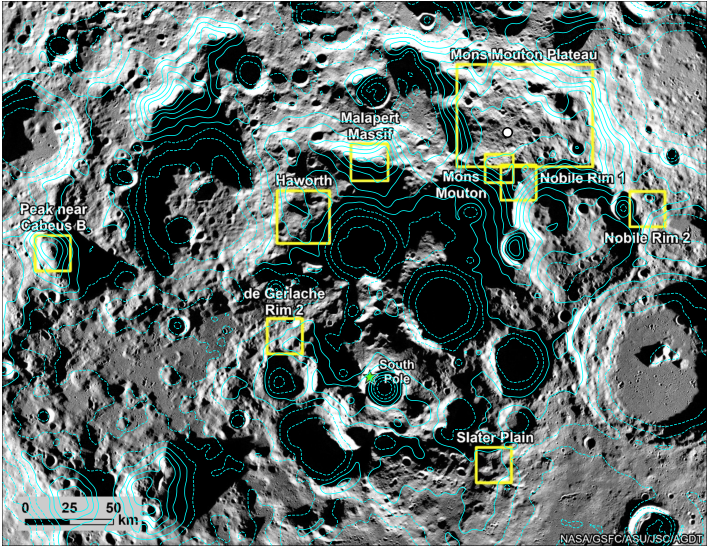

In [7]:
import matplotlib.pyplot as plt
import pooch

# The calibration applies to this exact image, so the checksum is pinned
map_file = pooch.retrieve('https://www.nasa.gov/wp-content/uploads/2024/10/artemis-landing-region-candidates.jpg',
                          known_hash='sha256:fd68f6631236b90b1352d4b41c1f70a25fdd45343d6864531c21a92be8526789')
image = plt.imread(map_file)

px_y, px_x = np.mgrid[0:image.shape[0]:3, 0:image.shape[1]:3]
lon, lat = polar_km_to_lonlat((px_x - X0)/PX_PER_KM, (Y0 - px_y)/PX_PER_KM)
nlat, nlon = grid_topo.data.shape
topo = map_coordinates(grid_topo.data, [(90 - lat)/180*(nlat - 1), (lon % 360)/360*(nlon - 1)], order=1)

lat_im2, lon_im2 = np.radians(-84.7906), np.radians(29.1957)
r_im2 = 2*R_MOON*np.tan((np.pi/2 + lat_im2)/2)

fig_check, ax = plt.subplots(figsize=(8, 6.2))
ax.imshow(image)
ax.contour(px_x, px_y, topo, levels=np.arange(-6000, 8000, 1000), colors='cyan', linewidths=0.5)
ax.plot(X0 + PX_PER_KM*r_im2*np.sin(lon_im2), Y0 - PX_PER_KM*r_im2*np.cos(lon_im2), 'o', color='white', mec='black')
ax.set_axis_off()
plt.show()